# Lecture notebook on Linear Regression

In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt  
from sklearn.model_selection import train_test_split 
from sklearn.linear_model import LinearRegression
from sklearn import metrics
from sklearn.datasets import load_diabetes
from sklearn.metrics import mean_squared_error, r2_score
from scipy.stats import pearsonr




In [2]:
X = 2 * np.random.rand(100,1)
y = 4 +3 *X +np.random.rand(100,1)


Text(0.5, 1.0, 'scatter plot')

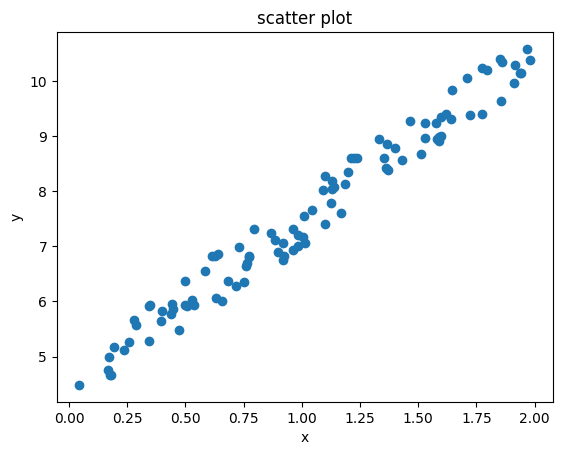

In [3]:
plt.scatter(X,y)
plt.xlabel("x")
plt.ylabel("y")
plt.title("scatter plot")

## LinReg solver mit OLS

In [4]:
class MyLinReg:

    def fit(self, X, y):
        X_b = np.c_[np.ones((100,1)),X]
        self.weights_ =  np.linalg.inv(X_b.T.dot(X_b)).dot(X_b.T).dot(y)


    def predict(self, Xpred):
        X_temp = np.c_[np.ones((100,1)),Xpred]
        y_predict = X_temp.dot(self.weights_)
        return y_predict


In [5]:
mlr = MyLinReg()

mlr.fit(X,y)

In [6]:
print(mlr.weights_)

[[4.47016013]
 [3.0174443 ]]


## LinReg in SKLearn

In [7]:
#loading diabetes data

diabetes=load_diabetes()
print(diabetes.DESCR)


.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level

Note: Each of these 10 feature variables have bee

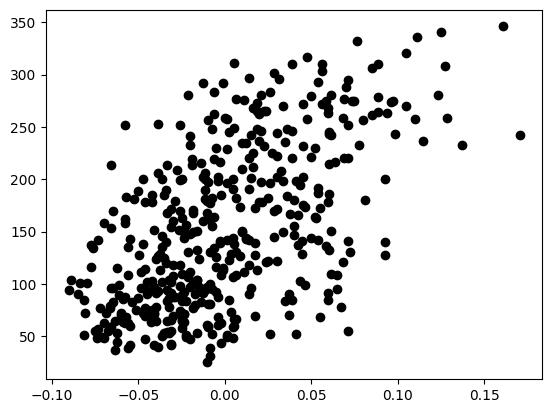

(422, 1)


In [8]:
#Wir nehmen das 3te Merkmal
diabetes_X = diabetes.data[:, np.newaxis, 2]


plt.scatter(diabetes_X, diabetes.target,  color='black')
plt.show()

# Split the data into training/testing sets. Good?
diabetes_X_train = diabetes_X[:-20]
diabetes_X_test = diabetes_X[-20:]

# Split the targets into training/testing sets
diabetes_y_train = diabetes.target[:-20]
diabetes_y_test = diabetes.target[-20:]

print(diabetes_X_train.shape)

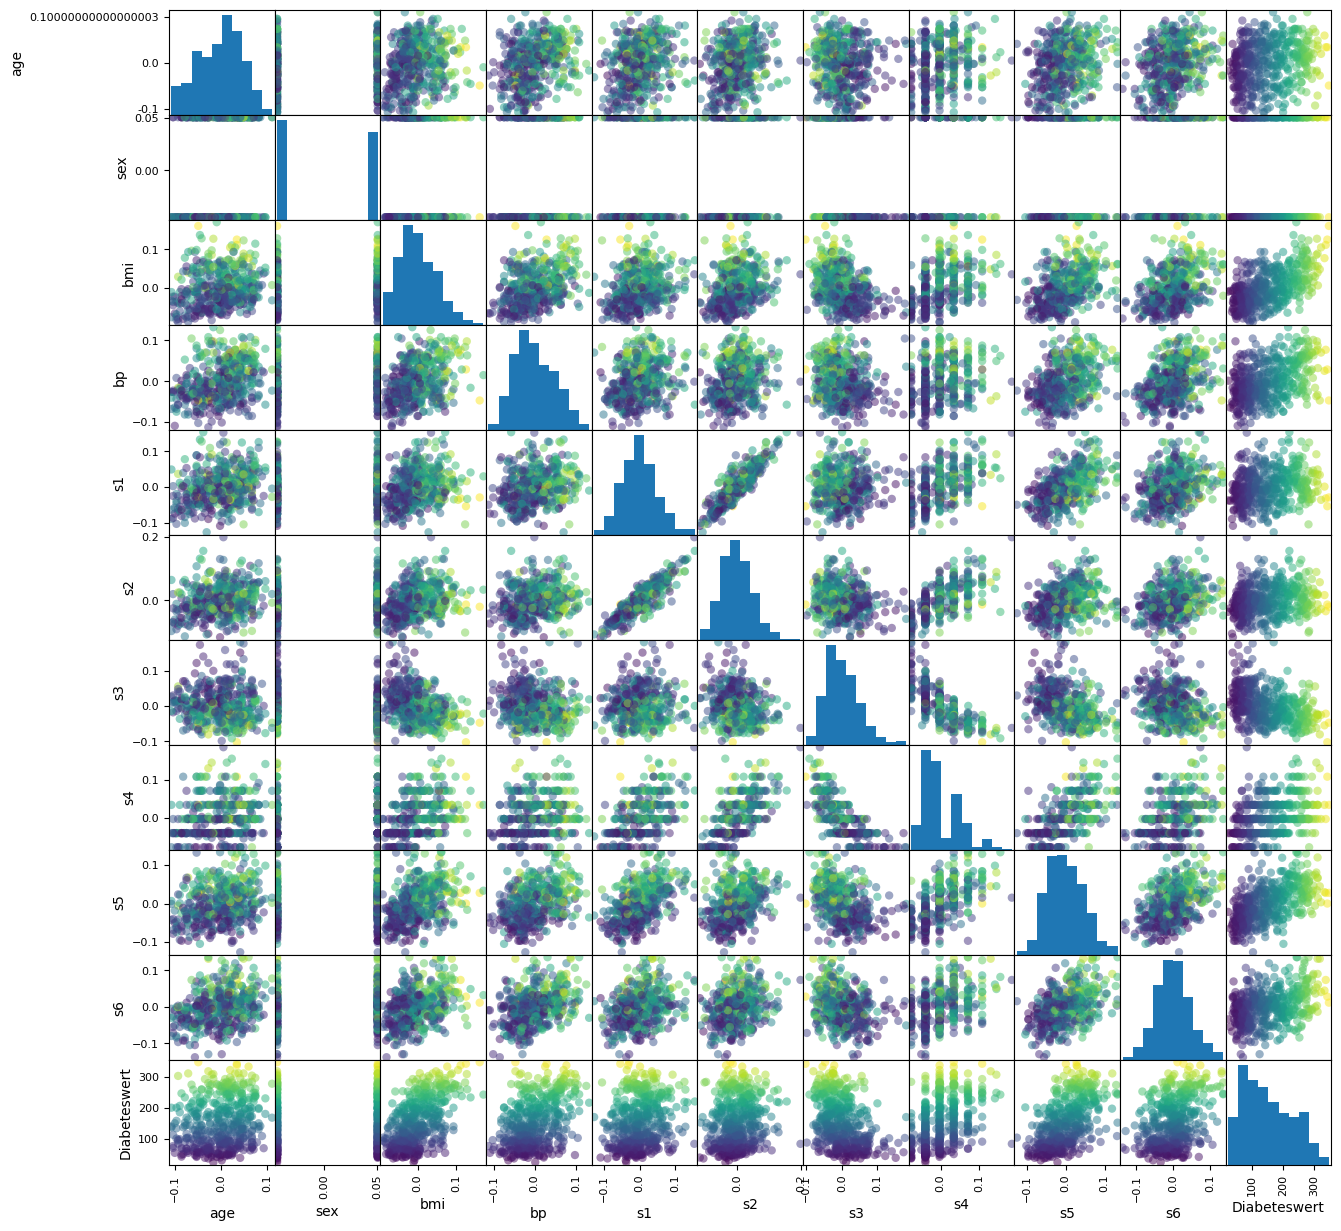

In [9]:
import pandas as pd
diabetes_dataframe = pd.DataFrame(diabetes['data'], columns=diabetes.feature_names)
diabetes_dataframe['Diabeteswert'] = diabetes['target']
grr = pd.plotting.scatter_matrix(diabetes_dataframe, c=diabetes['target'], figsize=(15,15), marker='o' )


### Training


Bias: 152.91886182616113
Steigung: 938.237861251352
Mean squared error: 2548.07
Pearson r=0.74


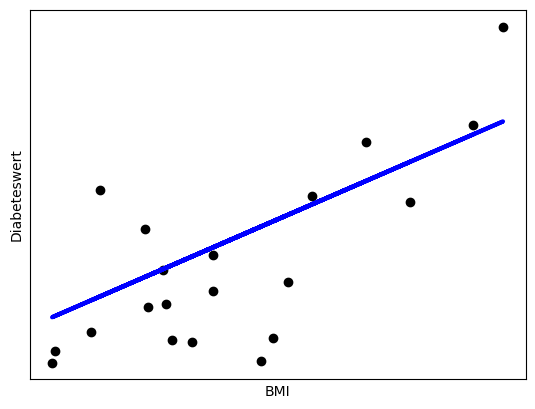

In [10]:

# Create linear regression object
lr = LinearRegression()

# Train the model using the training sets
lr.fit(diabetes_X_train, diabetes_y_train)

# Make predictions using the testing set
diabetes_y_pred = lr.predict(diabetes_X_test)

# The mean squared error

print("Bias: {}".format(lr.intercept_))
print("Steigung: {}".format(lr.coef_[0]))

print("Mean squared error: %.2f"
      % mean_squared_error(diabetes_y_test, diabetes_y_pred))
# Explained variance score: 1 is perfect prediction
r=pearsonr(diabetes_y_test, diabetes_y_pred)
print('Pearson r=%.2f' % r[0])

# Plot outputs
plt.scatter(diabetes_X_test, diabetes_y_test,  color='black')
plt.plot(diabetes_X_test, diabetes_y_pred, color='blue', linewidth=3)

plt.xticks(())
plt.yticks(())
plt.xlabel('BMI')
plt.ylabel('Diabeteswert') 

plt.show()

Text(0, 0.5, 'Diabeteswert vorhergesagt')

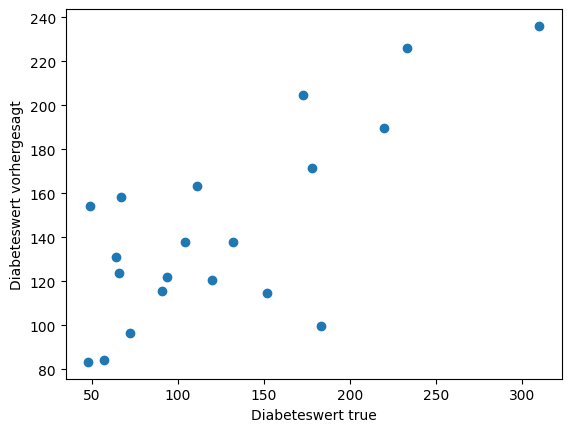

In [11]:
plt.scatter(diabetes_y_test,diabetes_y_pred)
plt.xlabel('Diabeteswert true')
plt.ylabel('Diabeteswert vorhergesagt')

### Multiple Lineare Regression


In [12]:
X_train, X_test, y_train,y_test  = train_test_split(diabetes['data'],diabetes['target'],random_state=42)

lr_mult = LinearRegression()


# Train the model using the training sets
lr_mult.fit(X_train, y_train)

# Make predictions using the testing set
y_pred = lr_mult.predict(X_test)

# The mean squared error

print("Bias: {}".format(lr_mult.intercept_))
print("Steigung: {}".format(lr_mult.coef_[0]))

print("Mean squared error: %.2f"
      % mean_squared_error(y_test, y_pred))

# Explained variance score: 1 is perfect prediction
r=pearsonr(y_test, y_pred)
print('Pearson r=%.2f' % r[0])



Bias: 151.6651755919933
Steigung: 47.749680540518845
Mean squared error: 2848.31
Pearson r=0.70


## Evaluation


Pearson r = 0.70


Text(0, 0.5, 'Diabeteswert vorhergesagt')

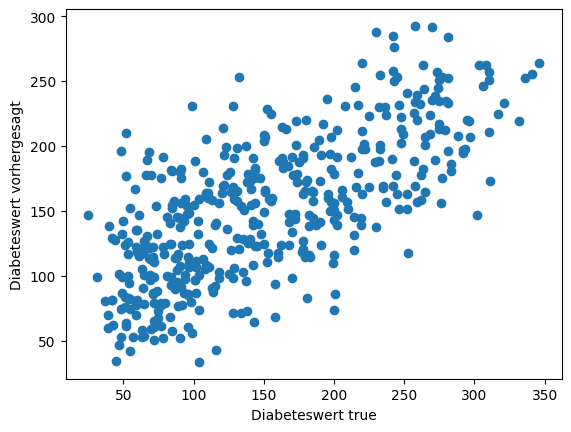

In [13]:
from sklearn.model_selection import LeaveOneOut

loo = LeaveOneOut()
lr_mult = LinearRegression()
#accuracies=[]

X=diabetes['data']
y=diabetes['target']
scores=[]
for train_indices, test_indices in loo.split(X, y):
    #print("TRAIN:", train_indices, "TEST:", test_indices)
    lr_mult.fit(X[train_indices],y[train_indices])
    pred=lr_mult.predict(X[test_indices])
    scores.append(pred)


r=pearsonr(y,np.asarray(scores).flatten())[0]
print('Pearson r = %.2f' %r)


plt.scatter(y,np.asarray(scores).flatten())
plt.xlabel('Diabeteswert true')
plt.ylabel('Diabeteswert vorhergesagt')

